In [1]:
# Load and clean
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("water_levels.csv", parse_dates=["date"], index_col="date")
df["depth_to_water_m"] = df["depth_to_water_m"].replace(-999, np.nan)
df["depth_clean"] = df["depth_to_water_m"].interpolate()

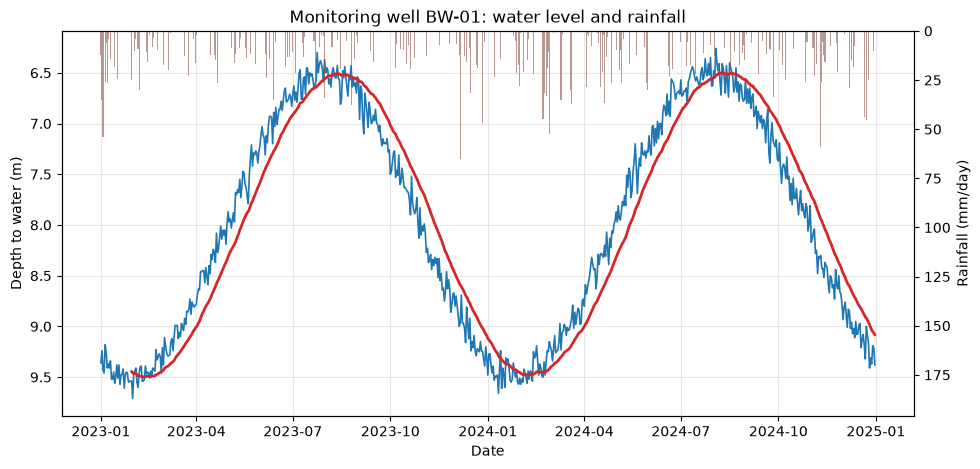

In [8]:
# Water level on the main axis
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(df.index, df["depth_clean"], color="tab:blue", linewidth=1.2)
ax1.plot(df.index, df["depth_clean"].rolling(30).mean(), color="tab:red", linewidth=2, label="30-day average")
ax1.set_ylabel("Depth to water (m)")
ax1.set_xlabel("Date")
ax1.invert_yaxis()

# Rainfall on a second axis
ax2 = ax1.twinx()
ax2.bar(df.index, df["rainfall_mm"], color="tab:brown", alpha=0.6, width=1.0)
ax2.set_ylabel("Rainfall (mm/day)")
ax2.set_ylim(df["rainfall_mm"].max() * 3, 0)

# Finish and save
ax1.set_title("Monitoring well BW-01: water level and rainfall")
ax1.grid(alpha=0.3)
fig.savefig("hydrograph_BW-01.png", dpi=200, bbox_inches="tight")
plt.show()


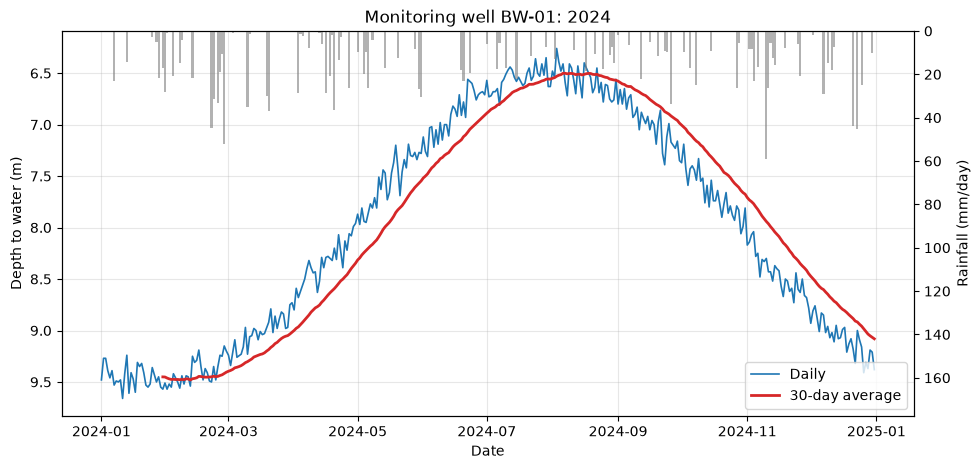

In [9]:
df24 = df.loc["2024"]

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(df24.index, df24["depth_clean"], color="tab:blue", linewidth=1.2, label="Daily")
ax1.plot(df24.index, df24["depth_clean"].rolling(30).mean(), color="tab:red", linewidth=2, label="30-day average")
ax1.set_ylabel("Depth to water (m)")
ax1.set_xlabel("Date")
ax1.invert_yaxis()

ax2 = ax1.twinx()
ax2.bar(df24.index, df24["rainfall_mm"], color="tab:gray", alpha=0.6, width=1.0)
ax2.set_ylabel("Rainfall (mm/day)")
ax2.set_ylim(df24["rainfall_mm"].max() * 3, 0)

ax1.set_title("Monitoring well BW-01: 2024")
ax1.grid(alpha=0.3)
ax1.legend(loc="lower right")
fig.savefig("hydrograph_BW-01_2024.png", dpi=200, bbox_inches="tight")
plt.show()